# VioGén 2 · Module 1: how the 2025 reform reshaped the risk categories that structure police follow-up

**Question for this module.** VioGén 2 changed *how cases are classified and administered*: the lowest
category ("No apreciado") was abolished from July 2025, and a new administrative status ("Supervisados")
appears in the statistics from November 2024. This notebook uses the official monthly bulletins from
January 2018 to September 2026 to show **what changed in the published classifications, where, and what
the published data cannot tell us**. Starting in 2018 lets the earlier protocol change (Instrucción 4/2019, in
force 13 March 2019) serve as a benchmark for the 2025 one. It is an investigation of a socio-technical decision process, *not*
an audit of predictive accuracy.

**What the data are.** End-of-month *stocks* of VioGén cases (a case = one victim–aggressor pair), from the
Delegación del Gobierno contra la Violencia de Género's *Boletín estadístico mensual* (BEM). Every table
was extracted from the official PDFs and checked: each row adds up, provinces add up to their region,
regions and police institutions add up to the national total. See [Methods and limitations](../../docs/01_statistics/METHODS_AND_LIMITATIONS.md).

**What the data are not.** They do not contain the 2025 scoring algorithm, individual case trajectories,
officer override records, or the protection actually delivered.

Run the cells from top to bottom. In Google Colab, the first cell asks you to upload the package ZIP.

In [1]:
# 0. Find the repository, locally or in Google Colab.
from pathlib import Path
import tempfile
import zipfile

marker = Path('data/01_statistics/national_monthly_verified.csv')
cwd = Path.cwd()
repo = next((p for p in (cwd, *cwd.parents) if (p / marker).is_file()), None)
if repo is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Open the notebook inside the VioGen-Risk-Assessment repository.') from None
    uploaded = files.upload()
    archive = next((name for name in uploaded if name.lower().endswith('.zip')), None)
    if archive is None:
        raise ValueError('Choose the repository ZIP.')
    unpacked = Path(tempfile.mkdtemp(prefix='viogen-'))
    with zipfile.ZipFile(archive) as source:
        source.extractall(unpacked)
    candidates = [p for p in (unpacked, *unpacked.iterdir()) if (p / marker).is_file()]
    if len(candidates) != 1:
        raise FileNotFoundError('The ZIP must contain the repository and its data/01_statistics folder.')
    repo = candidates[0]
data_dir = repo / 'data' / '01_statistics'
figure_dir = repo / 'figures' / '01_statistics'
scripts_dir = repo / 'scripts' / '01_statistics'

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
nat  = pd.read_csv(data_dir / 'national_monthly_verified.csv', parse_dates=['date'])
reg  = pd.read_csv(data_dir / 'regional_monthly_panel.csv', parse_dates=['date'])
prov = pd.read_csv(data_dir / 'provincial_monthly_panel.csv', parse_dates=['date'])
pol  = pd.read_csv(data_dir / 'police_force_monthly_panel.csv', parse_dates=['date'])
cov  = pd.read_csv(data_dir / 'month_by_month_coverage.csv')
val  = pd.read_csv(data_dir / 'validation_report.csv')
err  = pd.read_csv(data_dir / 'extraction_errors.csv')
chg  = pd.read_csv(data_dir / 'national_changelog.csv')
print(f'national months: {len(nat)} | regional rows: {len(reg)} | provincial rows: {len(prov)} | police-institution rows: {len(pol)}')

national months: 106 | regional rows: 1767 | provincial rows: 4836 | police-institution rows: 1662


## 1. Coverage: what is actually in the dataset

In [3]:
tab = cov.pivot(index='month', columns='breakdown', values='status')
summary = cov.assign(ok=cov.status.str.startswith('extracted and reconciled')).groupby('breakdown').ok.agg(['sum','count'])
summary.columns = ['months extracted and reconciled', 'months in window']
display(summary)
print('Months not fully extracted:')
display(tab[~tab.apply(lambda r: r.str.startswith('extracted and reconciled').all(), axis=1)])

,months extracted and reconciled,months in window
breakdown,,
national,96,106
police forces,70,106
provincial,93,106
regional,93,106


Months not fully extracted:


breakdown,national,police forces,provincial,regional
month,,,,
2018-01,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)
2018-02,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)
2018-03,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)
2018-04,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)
2018-05,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)
2018-06,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)
2018-07,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)
2018-08,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)
2018-09,extracted and reconciled (PDF text layer),not available: police-institution table first ...,extracted and reconciled (PDF text layer),extracted and reconciled (PDF text layer)


## 2. Independent re-check of every table in this notebook

The extractor already refused any table that did not reconcile. The cells below re-run the arithmetic
from the CSVs alone, so the checks do not depend on the extraction code.

In [4]:
LEV = ['no_appreciable','low','medium','high','extreme']
def row_ok(df):
    d = df[df.risk_levels_reported == True]
    lv = d[LEV].fillna(0).sum(axis=1)
    return (lv == d.active).all()
checks = {'regional rows: levels sum to active': row_ok(reg),
          'provincial rows: levels sum to active': row_ok(prov),
          'police rows: levels sum to active': row_ok(pol)}
# regions (publishing levels) sum to the national total, month by month
r = reg[reg.risk_levels_reported == True].groupby('date')[['low','medium','high','extreme','active']].sum()
n = nat.set_index('date')[['low','medium','high','extreme','active']]
checks['17 regions sum to national, every month'] = (r == n.loc[r.index]).all().all()
p = prov[prov.risk_levels_reported == True].groupby('date')[['low','medium','high','extreme','active']].sum()
checks['45 province-equivalents sum to national, every month'] = (p == n.loc[p.index]).all().all()
f = pol[pol.risk_levels_reported == True].groupby('date')[['low','medium','high','extreme','active']].sum()
checks['police institutions sum to national, every month'] = (f == n.loc[f.index]).all().all()
display(pd.Series(checks, name='passes'))
print('validation_report.csv:', val.result.value_counts().to_dict())
print('Every row that is not a pass (FAIL = arithmetic failure; tables that fail are excluded from the panels):')
display(val[val.result != 'pass'])

regional rows: levels sum to active                     True
provincial rows: levels sum to active                   True
police rows: levels sum to active                       True
17 regions sum to national, every month                 True
45 province-equivalents sum to national, every month    True
police institutions sum to national, every month        True
Name: passes, dtype: bool

validation_report.csv: {'pass': 713, 'not available': 45, 'FAIL': 8, 'corrected: official PDF value used': 1}
Every row that is not a pass (FAIL = arithmetic failure; tables that fail are excluded from the panels):


,month,table,check,result,detail
4,2018-01,police forces,table present in bulletin,not available,police-institution table first printed in the ...
9,2018-02,police forces,table present in bulletin,not available,police-institution table first printed in the ...
14,2018-03,police forces,table present in bulletin,not available,police-institution table first printed in the ...
19,2018-04,police forces,table present in bulletin,not available,police-institution table first printed in the ...
24,2018-05,police forces,table present in bulletin,not available,police-institution table first printed in the ...
29,2018-06,police forces,table present in bulletin,not available,police-institution table first printed in the ...
34,2018-07,police forces,table present in bulletin,not available,police-institution table first printed in the ...
39,2018-08,police forces,table present in bulletin,not available,police-institution table first printed in the ...
44,2018-09,police forces,table present in bulletin,not available,police-institution table first printed in the ...
49,2018-10,police forces,table present in bulletin,not available,police-institution table first printed in the ...


### Corrections to the national series received from the previous stage
Every month with an official bulletin was re-extracted from the PDF. The changelog lists values that
differed from the series supplied in the reference, and press-relay months that the official PDF confirmed.

In [5]:
display(chg)

,date,field,previous_value,corrected_value,previous_source,previous_source_kind,corrected_source,reason
0,2025-11-30,all level counts and active total,press relay,unchanged,https://efe.com/espana/2025-12-10/ninas-adoles...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,press-relay figures confirmed exactly by the o...
1,2025-12-31,all level counts and active total,press relay,unchanged,https://www.europapress.es/castilla-y-leon/not...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,press-relay figures confirmed exactly by the o...
2,2026-01-31,high,953,933,https://efe.com/espana/2026-02-04/casos-protec...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,"value differs from the official bulletin, whic..."
3,2026-01-31,active,103481,103461,https://efe.com/espana/2026-02-04/casos-protec...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,"value differs from the official bulletin, whic..."
4,2026-02-28,all level counts and active total,press relay,unchanged,https://www.europapress.es/epsocial/igualdad/n...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,press-relay figures confirmed exactly by the o...
5,2026-03-31,all level counts and active total,press relay,unchanged,https://www.europapress.es/epsocial/igualdad/n...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,press-relay figures confirmed exactly by the o...
6,2026-04-30,all level counts and active total,press relay,unchanged,https://www.europapress.es/epsocial/igualdad/n...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,press-relay figures confirmed exactly by the o...
7,2026-05-31,all level counts and active total,press relay,unchanged,https://www.europapress.es/epsocial/igualdad/n...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,press-relay figures confirmed exactly by the o...
8,2026-06-30,all level counts and active total,press relay,unchanged,https://www.europapress.es/epsocial/igualdad/n...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,press-relay figures confirmed exactly by the o...
9,2026-07-31,all level counts and active total,press relay,unchanged,https://efeminista.com/espana-violencia-genero...,press relay of Interior statistics,https://violenciagenero.igualdad.gob.es/wp-con...,press-relay figures confirmed exactly by the o...


## 3. National series: the lowest category disappears, the higher categories barely move

`medium_plus` (medium + high + extreme) is the most comparable grouping across the July 2025 break, but it
is **not a constant construct**: the 2025 protocol also introduced new indicators and recalibrated
algorithms (not published), so the same woman need not receive the same level before and after.

,date,protocol_period,no_appreciable,low,medium,high,extreme,active,supervised,medium_plus_pct,high_plus_pct,verification_status
0,2018-01-31,2016 protocol (Instrucción 7/2016),26801.0,22692.0,4761.0,200.0,10.0,54464.0,NaN,9.1271,0.3856,"verified against official PDF: all rows, regio..."
1,2018-02-28,2016 protocol (Instrucción 7/2016),26379.0,22882.0,4731.0,198.0,13.0,54203.0,NaN,9.1176,0.3893,"verified against official PDF: all rows, regio..."
2,2018-03-31,2016 protocol (Instrucción 7/2016),26224.0,23147.0,4821.0,231.0,17.0,54440.0,NaN,9.3112,0.4555,"verified against official PDF: all rows, regio..."
3,2018-04-30,2016 protocol (Instrucción 7/2016),25933.0,23357.0,4767.0,188.0,14.0,54259.0,NaN,9.1579,0.3723,"verified against official PDF: all rows, regio..."
4,2018-05-31,2016 protocol (Instrucción 7/2016),25776.0,23591.0,4823.0,163.0,12.0,54365.0,NaN,9.1934,0.3219,"verified against official PDF: all rows, regio..."
...,...,...,...,...,...,...,...,...,...,...,...,...
101,2026-06-30,2025 protocol (VioGén 2 levels),NaN,87517.0,15065.0,1144.0,20.0,103746.0,4733.0,15.6430,1.1220,"verified against official PDF: all rows, regio..."
102,2026-07-31,2025 protocol (VioGén 2 levels),NaN,87855.0,15632.0,1165.0,14.0,104666.0,4744.0,16.0616,1.1264,"verified against official PDF: all rows, regio..."
103,2026-08-31,2025 protocol (VioGén 2 levels),NaN,89016.0,16355.0,1157.0,21.0,106549.0,4617.0,16.4553,1.1056,"verified against official PDF: all rows, regio..."
104,2026-09-30,2025 protocol (VioGén 2 levels),NaN,89349.0,16470.0,1132.0,21.0,106972.0,4491.0,16.4744,1.0779,"verified against official PDF: all rows, regio..."


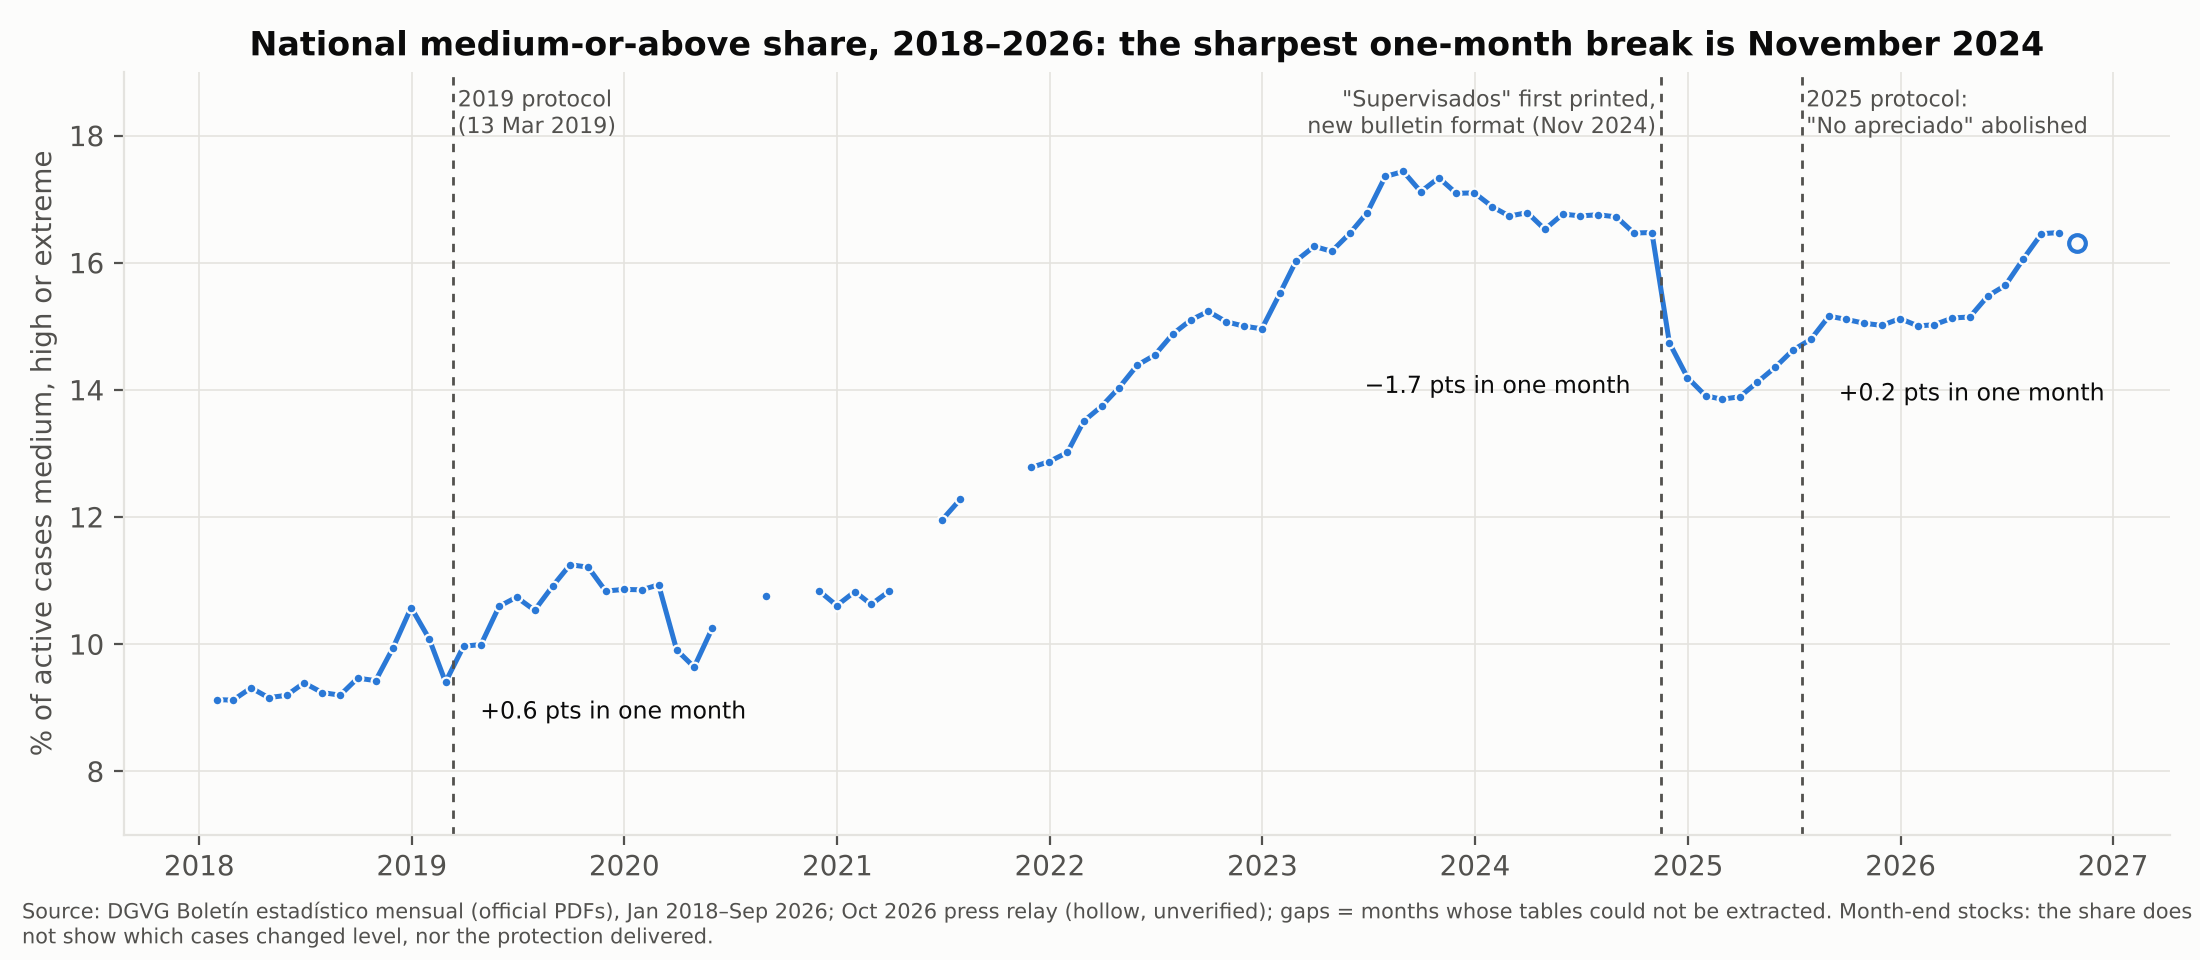

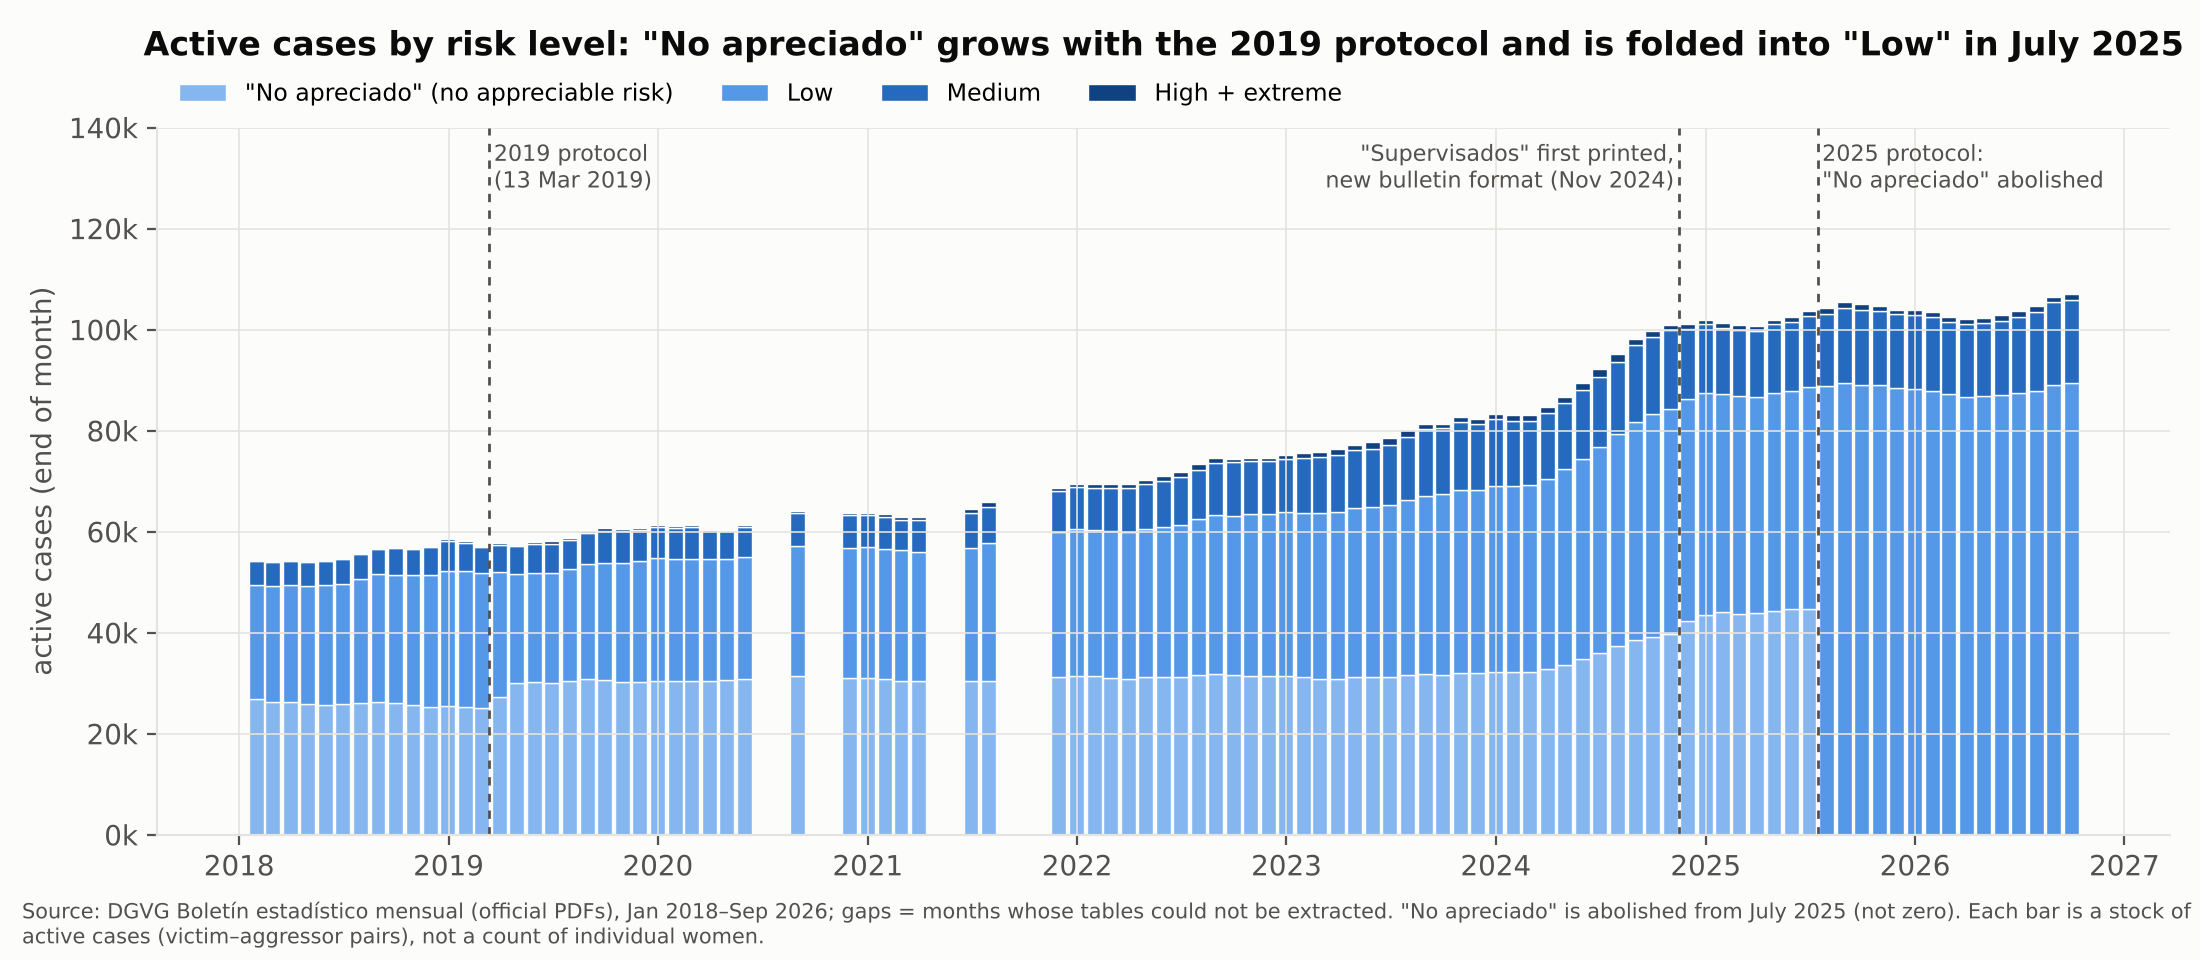

In [6]:
cols = ['date','protocol_period','no_appreciable','low','medium','high','extreme','active','supervised',
        'medium_plus_pct','high_plus_pct','verification_status']
display(nat[cols].assign(verification_status=nat.verification_status.str[:60]))
display(Image(filename=str(figure_dir / '01_national_medium_plus_share.png')))
display(Image(filename=str(figure_dir / '02_national_composition_counts.png')))

### Where the series actually breaks

The visual impression is of one break in July 2025. The month-to-month changes say otherwise.

In [7]:
v = nat[nat.verification_status.str.startswith('verified')].set_index('date')
v = v.reindex(pd.date_range(v.index.min(), v.index.max(), freq='ME'))   # gaps stay gaps: no diff across them
moves = v.medium_plus_pct.diff().dropna()
print('Largest one-month changes in the medium-or-above share, Jan 2018 - Sep 2026 (percentage points;')
print('only pairs of consecutive extracted months):')
display(moves.reindex(moves.abs().sort_values(ascending=False).index).head(5).round(2).to_frame('change, pp'))
lv = ['no_appreciable','low','medium','high','extreme','active']
display(v.loc[pd.to_datetime(['2019-02-28','2019-03-31','2019-04-30','2024-10-31','2024-11-30','2025-06-30','2025-07-31']),
             lv + ['supervised','medium_plus_pct']])

Largest one-month changes in the medium-or-above share, Jan 2018 - Sep 2026 (percentage points;
only pairs of consecutive extracted months):


,"change, pp"
2024-11-30,-1.74
2020-03-31,-1.02
2019-02-28,-0.68
2018-12-31,0.63
2020-05-31,0.61


,no_appreciable,low,medium,high,extreme,active,supervised,medium_plus_pct
2019-02-28,25071.0,26691.0,5183.0,179.0,10.0,57134.0,NaN,9.4025
2019-03-31,27201.0,24755.0,5365.0,367.0,19.0,57707.0,NaN,9.9659
2019-04-30,30121.0,21535.0,5429.0,287.0,19.0,57391.0,NaN,9.9929
2024-10-31,39803.0,44564.0,15491.0,1119.0,31.0,101008.0,NaN,16.4749
2024-11-30,42246.0,43948.0,13947.0,936.0,16.0,101093.0,2135.0,14.7379
2025-06-30,44661.0,43944.0,14014.0,1129.0,34.0,103782.0,7783.0,14.6239
2025-07-31,NaN,88772.0,14328.0,1070.0,17.0,104187.0,7564.0,14.7955


**Reading.**
- **November 2024 is the largest one-month change in the window.** The medium-or-above share falls by about 1.7
  points while the active total barely moves, and "No apreciado" grows. That month the bulletin also first prints
  *Supervisados* and switches to new institution names.
- **July 2025**, when the protocol formally changes, moves the share by about +0.2 points.
- **March 2019 was different.** The previous protocol change (Instrucción 4/2019, in force 13 March 2019) barely moved
  the medium-or-above share either. Its footprint is at the bottom of the scale: "No apreciado" jumps from 43.9% of active
  cases in February 2019 to 52.5% in April 2019, while "Low" shrinks.

For November 2024, two readings are possible, and the published data cannot tell them apart:

* a change in **classification practice** (the VioGén 2 platform was tested for seven months before its
  January 2025 presentation);
* a change in **how the statistics were compiled**.

This is a precise question for an interview with Interior or with the protocol's designers. The next section
narrows it.

### Break test: do the provinces move together?

A change in local practice spreads unevenly. A change made centrally (a scoring rule, the software, how the figures
are compiled) moves every province in the same month. For each month, the cell below counts how many of the 45
province-equivalents publishing risk levels moved in the same direction as the previous month. Only pairs of
consecutive extracted months count.

Medium-or-above share: months with the most provinces falling together


,provinces compared,% falling,% rising,"median change, pp"
2024-11-30,45,98.0,2.0,-1.53
2019-02-28,45,84.0,16.0,-0.79
2020-03-31,45,82.0,18.0,-0.64
2023-09-30,45,80.0,20.0,-0.36
2024-12-31,45,71.0,29.0,-0.52
2019-01-31,45,71.0,29.0,-0.47


"No apreciado" share: months with the most provinces rising together


,provinces compared,% falling,% rising,"median change, pp"
2019-04-30,45,2.0,98.0,5.08
2019-03-31,45,9.0,91.0,3.06
2024-11-30,45,9.0,91.0,2.38
2025-01-31,45,22.0,78.0,0.69
2024-12-31,45,24.0,76.0,0.93
2020-03-31,45,33.0,67.0,0.57


Ordinary month: median 47% of provinces falling (medium-or-above), 42% rising (No apreciado).


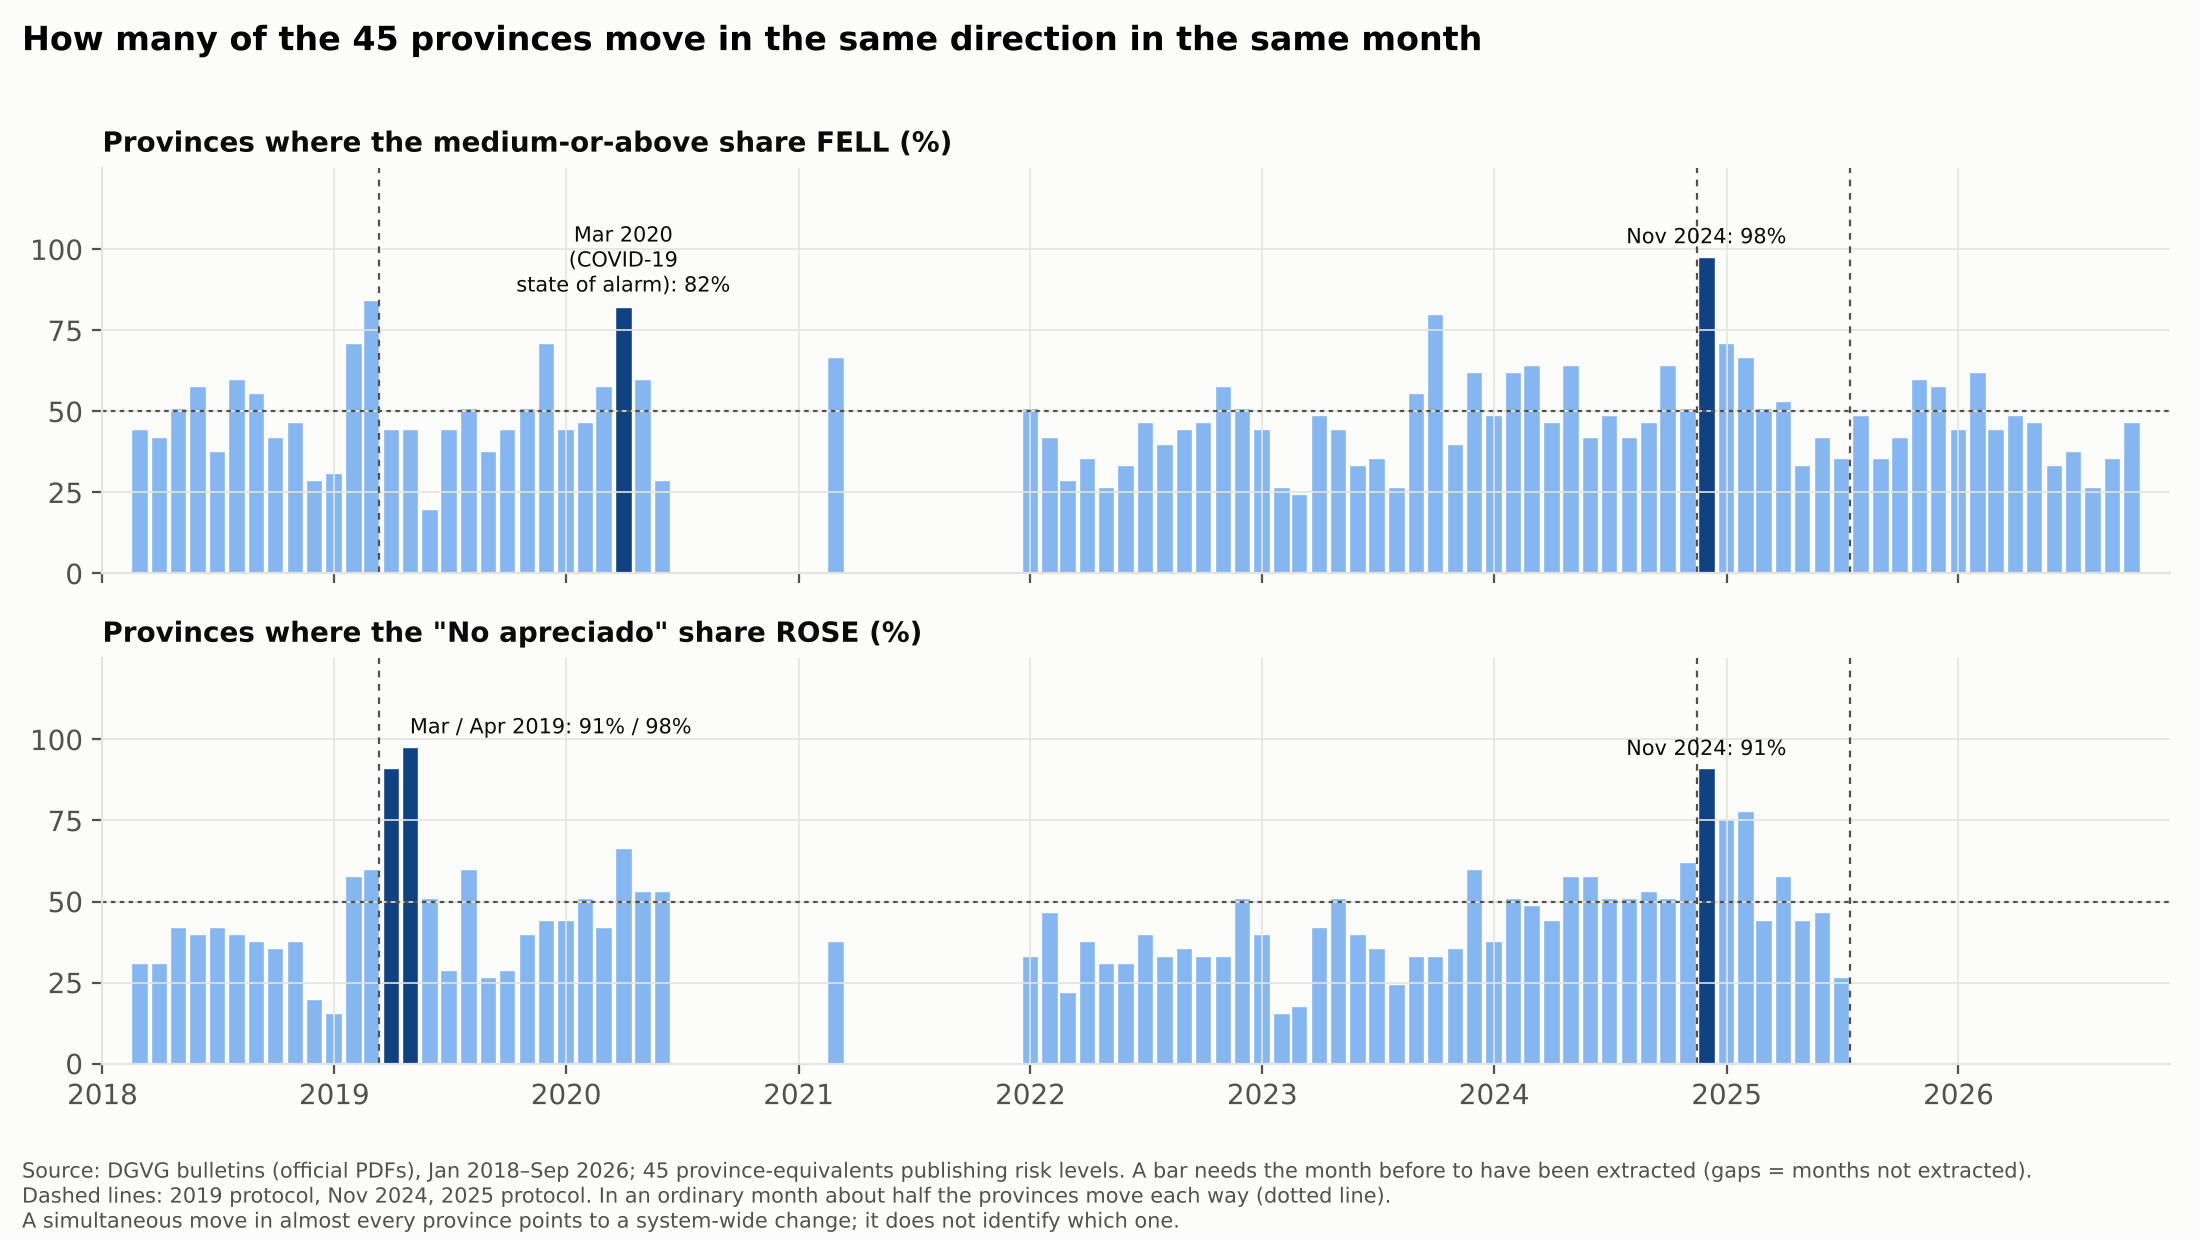

In [8]:
pr = prov[prov.risk_levels_reported == True].copy()
pr['na_pct'] = 100 * pr.no_appreciable / pr.active
allm = pd.date_range(pr.date.min(), pr.date.max(), freq='ME')
mp_w = pr.pivot_table(index='date', columns='unit', values='medium_plus_pct').reindex(allm)
na_w = pr.pivot_table(index='date', columns='unit', values='na_pct').reindex(allm)
def moving(w):
    d = w.diff(); n = d.notna().sum(axis=1)
    return pd.DataFrame({'provinces compared': n,
                         '% falling': (100 * (d < 0).sum(axis=1) / n).round(0),
                         '% rising': (100 * (d > 0).sum(axis=1) / n).round(0),
                         'median change, pp': d.median(axis=1).round(2)})[n > 0]
mpm, nam = moving(mp_w), moving(na_w[na_w.index <= '2025-06-30'])
print('Medium-or-above share: months with the most provinces falling together')
display(mpm.sort_values('% falling', ascending=False).head(6))
print('"No apreciado" share: months with the most provinces rising together')
display(nam.sort_values('% rising', ascending=False).head(6))
print(f"Ordinary month: median {mpm['% falling'].median():.0f}% of provinces falling (medium-or-above), "
      f"{nam['% rising'].median():.0f}% rising (No apreciado).")
display(Image(filename=str(figure_dir / '08_provinces_moving_together.png')))

In [9]:
# the same test on police institutions with at least 500 active cases (Oct -> Nov 2024)
q = pol[(pol.risk_levels_reported == True) & pol.date.isin(pd.to_datetime(['2024-10-31', '2024-11-30']))]
w = q.pivot_table(index='unit', columns='date', values=['medium_plus_pct', 'active'])
w = w[w[('active', pd.Timestamp('2024-10-31'))] >= 500]
chg_inst = (w[('medium_plus_pct', pd.Timestamp('2024-11-30'))] - w[('medium_plus_pct', pd.Timestamp('2024-10-31'))])
print(f'{(chg_inst < 0).sum()} of {len(chg_inst)} large institutions fell in November 2024 (percentage points):')
display(chg_inst.sort_values().round(1).to_frame('change Oct -> Nov 2024'))

11 of 13 large institutions fell in November 2024 (percentage points):


,change Oct -> Nov 2024
unit,
PL Illes Balears,-3.4
PL Comunidad de Madrid,-2.0
Guardia Civil,-2.0
PL Galicia,-1.9
Policía Nacional,-1.9
PL Castilla y León,-1.7
PL Región de Murcia,-1.2
PL Comunitat Valenciana,-1.1
PL Andalucía,-0.9


**Reading.**
- **November 2024 is the most synchronised fall in the medium-or-above share in the window.** In the publishing
  provinces the share fell in 44 of 45, against roughly half in an ordinary month, and "No apreciado" rose in most of
  them. The Guardia Civil, the Policía Nacional and most local police forces fell by similar amounts.
- **The shape matches the 2019 protocol change.** In March and April 2019, "No apreciado" rose in almost every province
  at once.
- **February 2019 also stands out.** 84% of provinces fell that month, two weeks before the 2019 protocol took
  effect. The bulletins give no explanation.
- **Simultaneity has other causes too.** The March 2020 COVID-19 state of alarm also moved most provinces together.
  A synchronised move shows that the cause was **system-wide**, not which system-wide change it was.

What this makes unlikely is a gradual, officer-by-officer shift in practice. What it leaves open is a scoring or
procedural change applied centrally versus a change in how the statistics were produced. That is the question to
put to Interior or the protocol's designers.

### The reform month: 30 June versus 31 July 2025

date,2025-06-30 00:00:00,2025-07-31 00:00:00,change
no_appreciable,44661.0,NaN,-44661.0
low,43944.0,88772.0,44828.0
medium,14014.0,14328.0,314.0
high,1129.0,1070.0,-59.0
extreme,34.0,17.0,-17.0
active,103782.0,104187.0,405.0
supervised,7783.0,7564.0,-219.0
inactive,745056.0,750494.0,5438.0
total,856621.0,862245.0,5624.0


June "No apreciado" + "Low" = 88,605; July "Low" = 88,772 (difference +167).
Medium-or-above share: 14.62% -> 14.80%


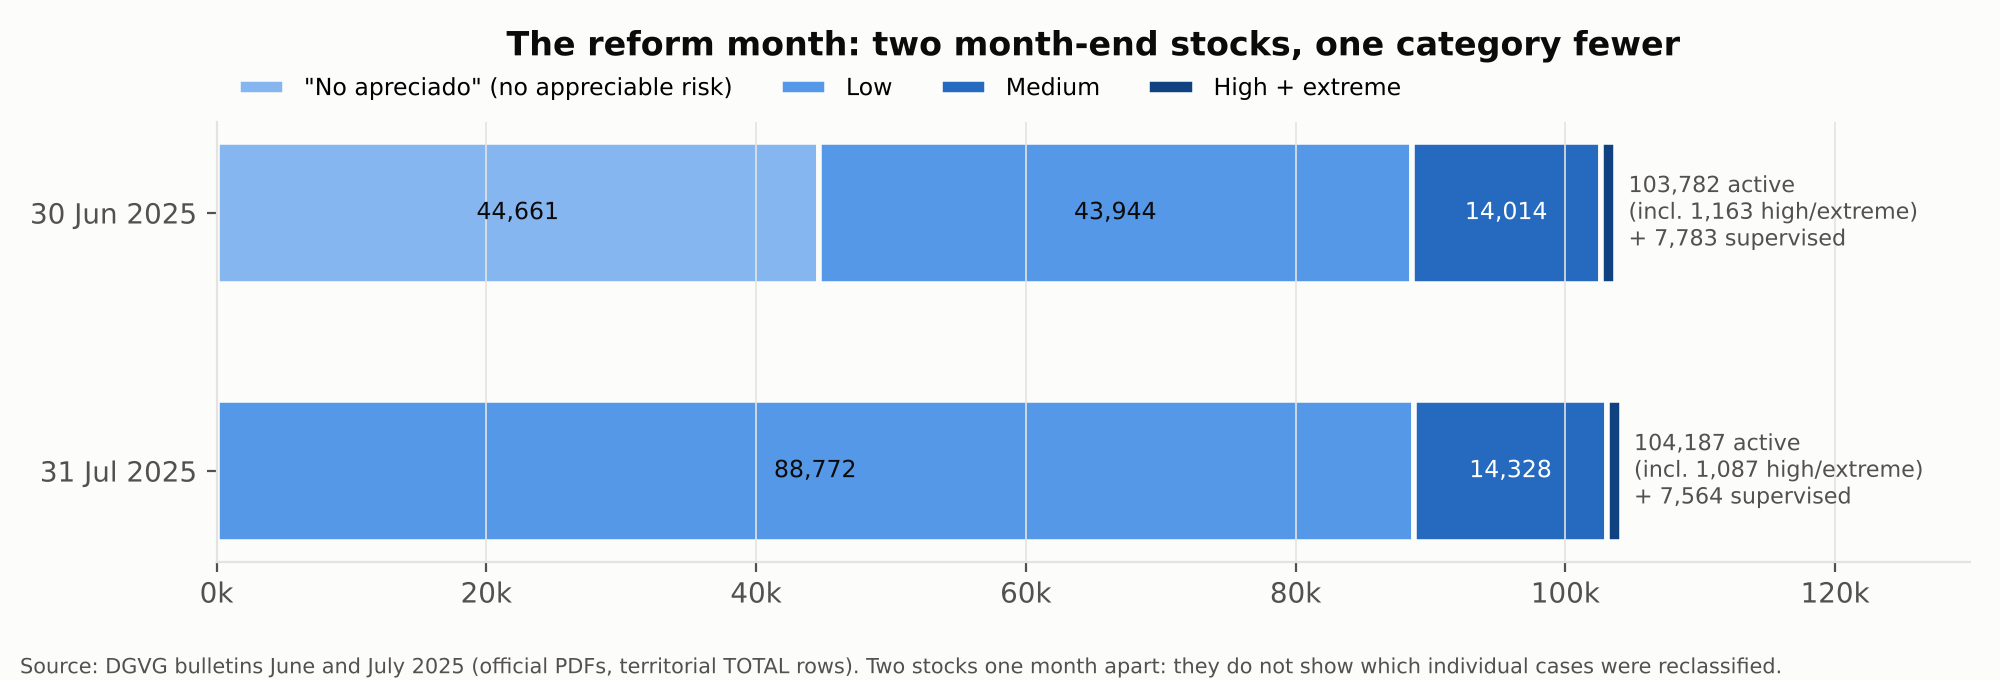

In [10]:
jj = nat[nat.date.isin(pd.to_datetime(['2025-06-30','2025-07-31']))].set_index('date')
comp = jj[['no_appreciable','low','medium','high','extreme','active','supervised','inactive','total']].T
comp['change'] = comp.iloc[:,1].fillna(0) - comp.iloc[:,0].fillna(0)
display(comp)
lowest_jun = jj.iloc[0][['no_appreciable','low']].sum(); low_jul = jj.iloc[1]['low']
print(f'June "No apreciado" + "Low" = {lowest_jun:,.0f}; July "Low" = {low_jul:,.0f} '
      f'(difference {low_jul - lowest_jun:+,.0f}).')
print(f"Medium-or-above share: {jj.iloc[0].medium_plus_pct:.2f}% -> {jj.iloc[1].medium_plus_pct:.2f}%")
display(Image(filename=str(figure_dir / '03_june_july_2025_transition.png')))

**Reading.** In one month the "No apreciado" category (44,661 cases on 30 June) disappears and "Low"
roughly doubles, while the medium-or-above share moves by a fraction of a point. The published stocks are
consistent with the old lowest category being absorbed into "Low", but they **cannot show** which cases moved
where: this is a comparison of two stocks, and the counts also change through new entries, closures and
re-assessments during the month.

## 4. A new administrative status: "Supervisados"

The bulletins print a *Supervisados* column from **November 2024**, eight months before the category
change. Supervised cases are in a temporary special-follow-up phase before inactivation and are **not** in
the active count. Under the 2025 protocol, the choice between keeping a case active, supervising it or
inactivating it is a procedural decision with its own rules, so this column is one of the few published
traces of how follow-up is administered.

,date,active,supervised,supervised_per_100_active
82,2024-11-30,101093.0,2135.0,2.112
83,2024-12-31,101962.0,3359.0,3.294
84,2025-01-31,101254.0,4586.0,4.529
85,2025-02-28,100899.0,5597.0,5.547
86,2025-03-31,100723.0,6544.0,6.497
87,2025-04-30,101934.0,7042.0,6.908
88,2025-05-31,102575.0,7476.0,7.288
89,2025-06-30,103782.0,7783.0,7.499
90,2025-07-31,104187.0,7564.0,7.260
91,2025-08-31,105509.0,7092.0,6.722


Peak: 7,783 supervised cases on 30 Jun 2025; latest verified: 4,491 on 30 Sep 2026.


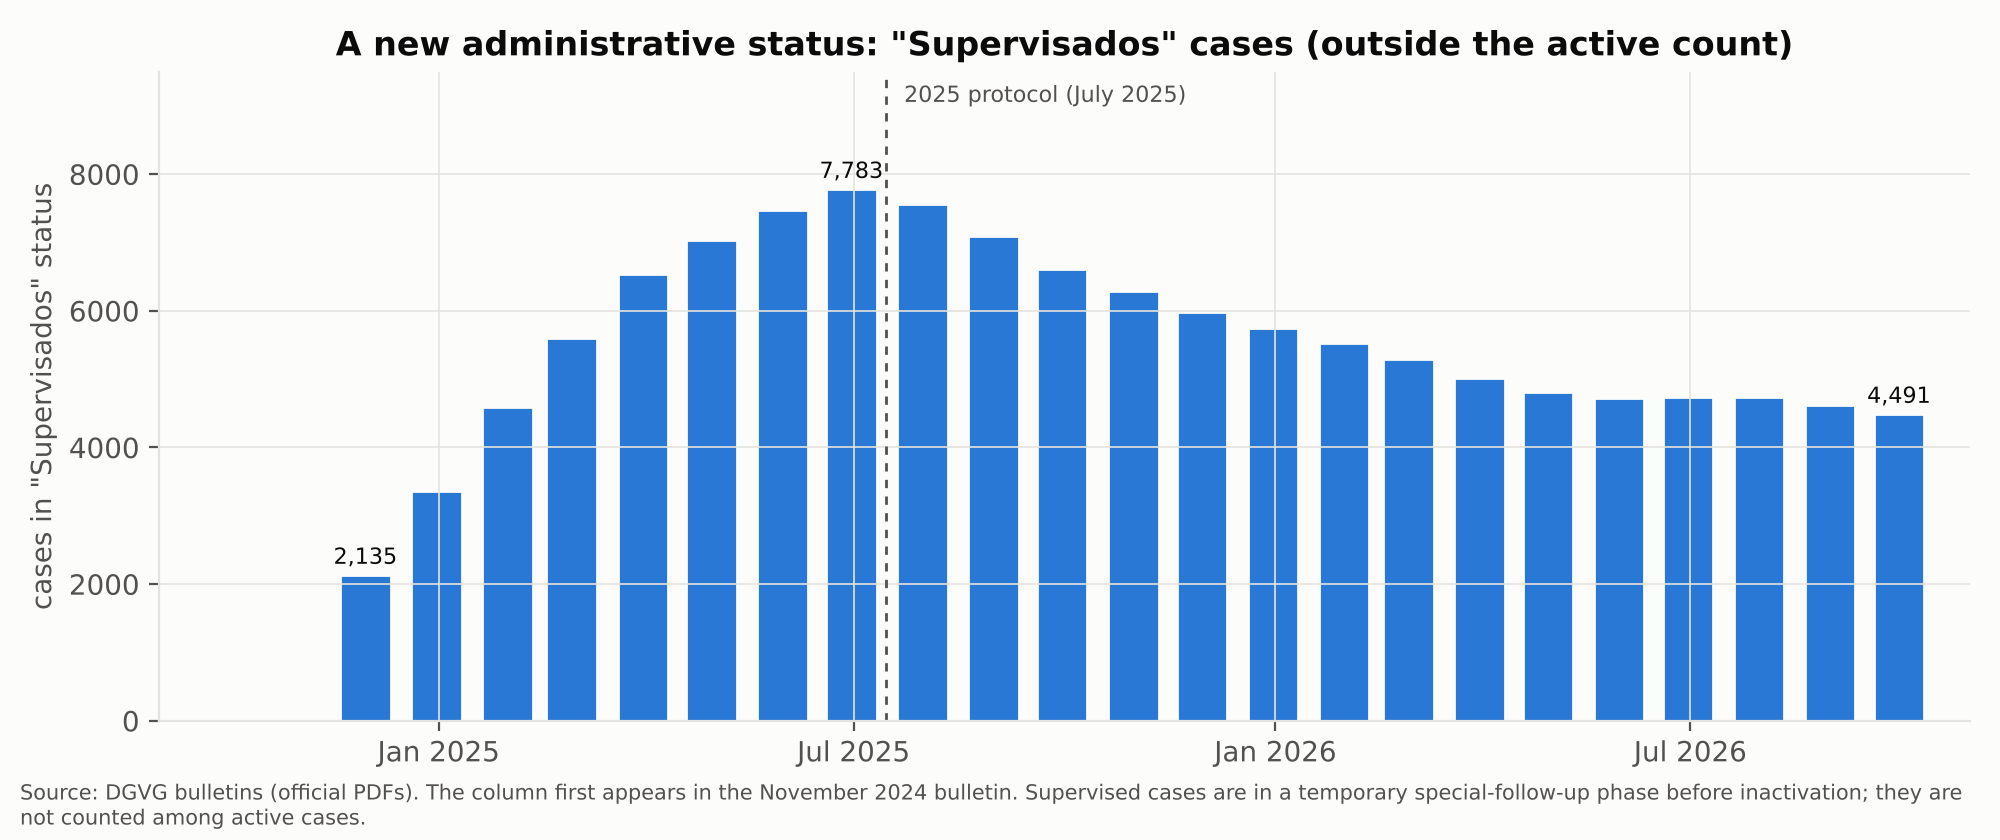

In [11]:
s = nat.dropna(subset=['supervised'])[['date','active','supervised','supervised_per_100_active']]
display(s)
pk = s.loc[s.supervised.idxmax()]
print(f"Peak: {pk.supervised:,.0f} supervised cases on {pk.date:%d %b %Y}; latest verified: "
      f"{s.iloc[-1].supervised:,.0f} on {s.iloc[-1].date:%d %b %Y}.")
display(Image(filename=str(figure_dir / '04_supervised_status.png')))

## 5. Regions and police institutions

Differences between territories or institutions reflect **different populations, case mixes, police forces
and practices together**. They are not measures of officer behaviour, overrides or bias.

,Jun 2024,Jun 2025,Jul 2025,Sep 2026
unit,,,,
La Rioja,27.9,24.1,24.4,23.9
Ceuta,38.9,19.0,21.0,22.4
Cantabria,20.7,20.0,19.4,21.7
Extremadura,20.2,19.7,19.5,21.2
Comunitat Valenciana,20.4,17.7,18.0,20.4
Illes Balears,20.6,17.0,17.7,19.4
Comunidad Foral de Navarra,20.3,17.4,17.8,19.2
Región de Murcia,18.2,17.2,18.0,18.8
Principado de Asturias,15.2,17.8,16.5,17.9


Spread of the regional medium-or-above share (percentage points), selected months:


,min,median,max
date,,,
2023-01-31,9.1,15.9,43.0
2025-06-30,6.4,17.0,24.1
2025-07-31,4.7,16.5,24.4
2026-09-30,8.4,17.9,23.9


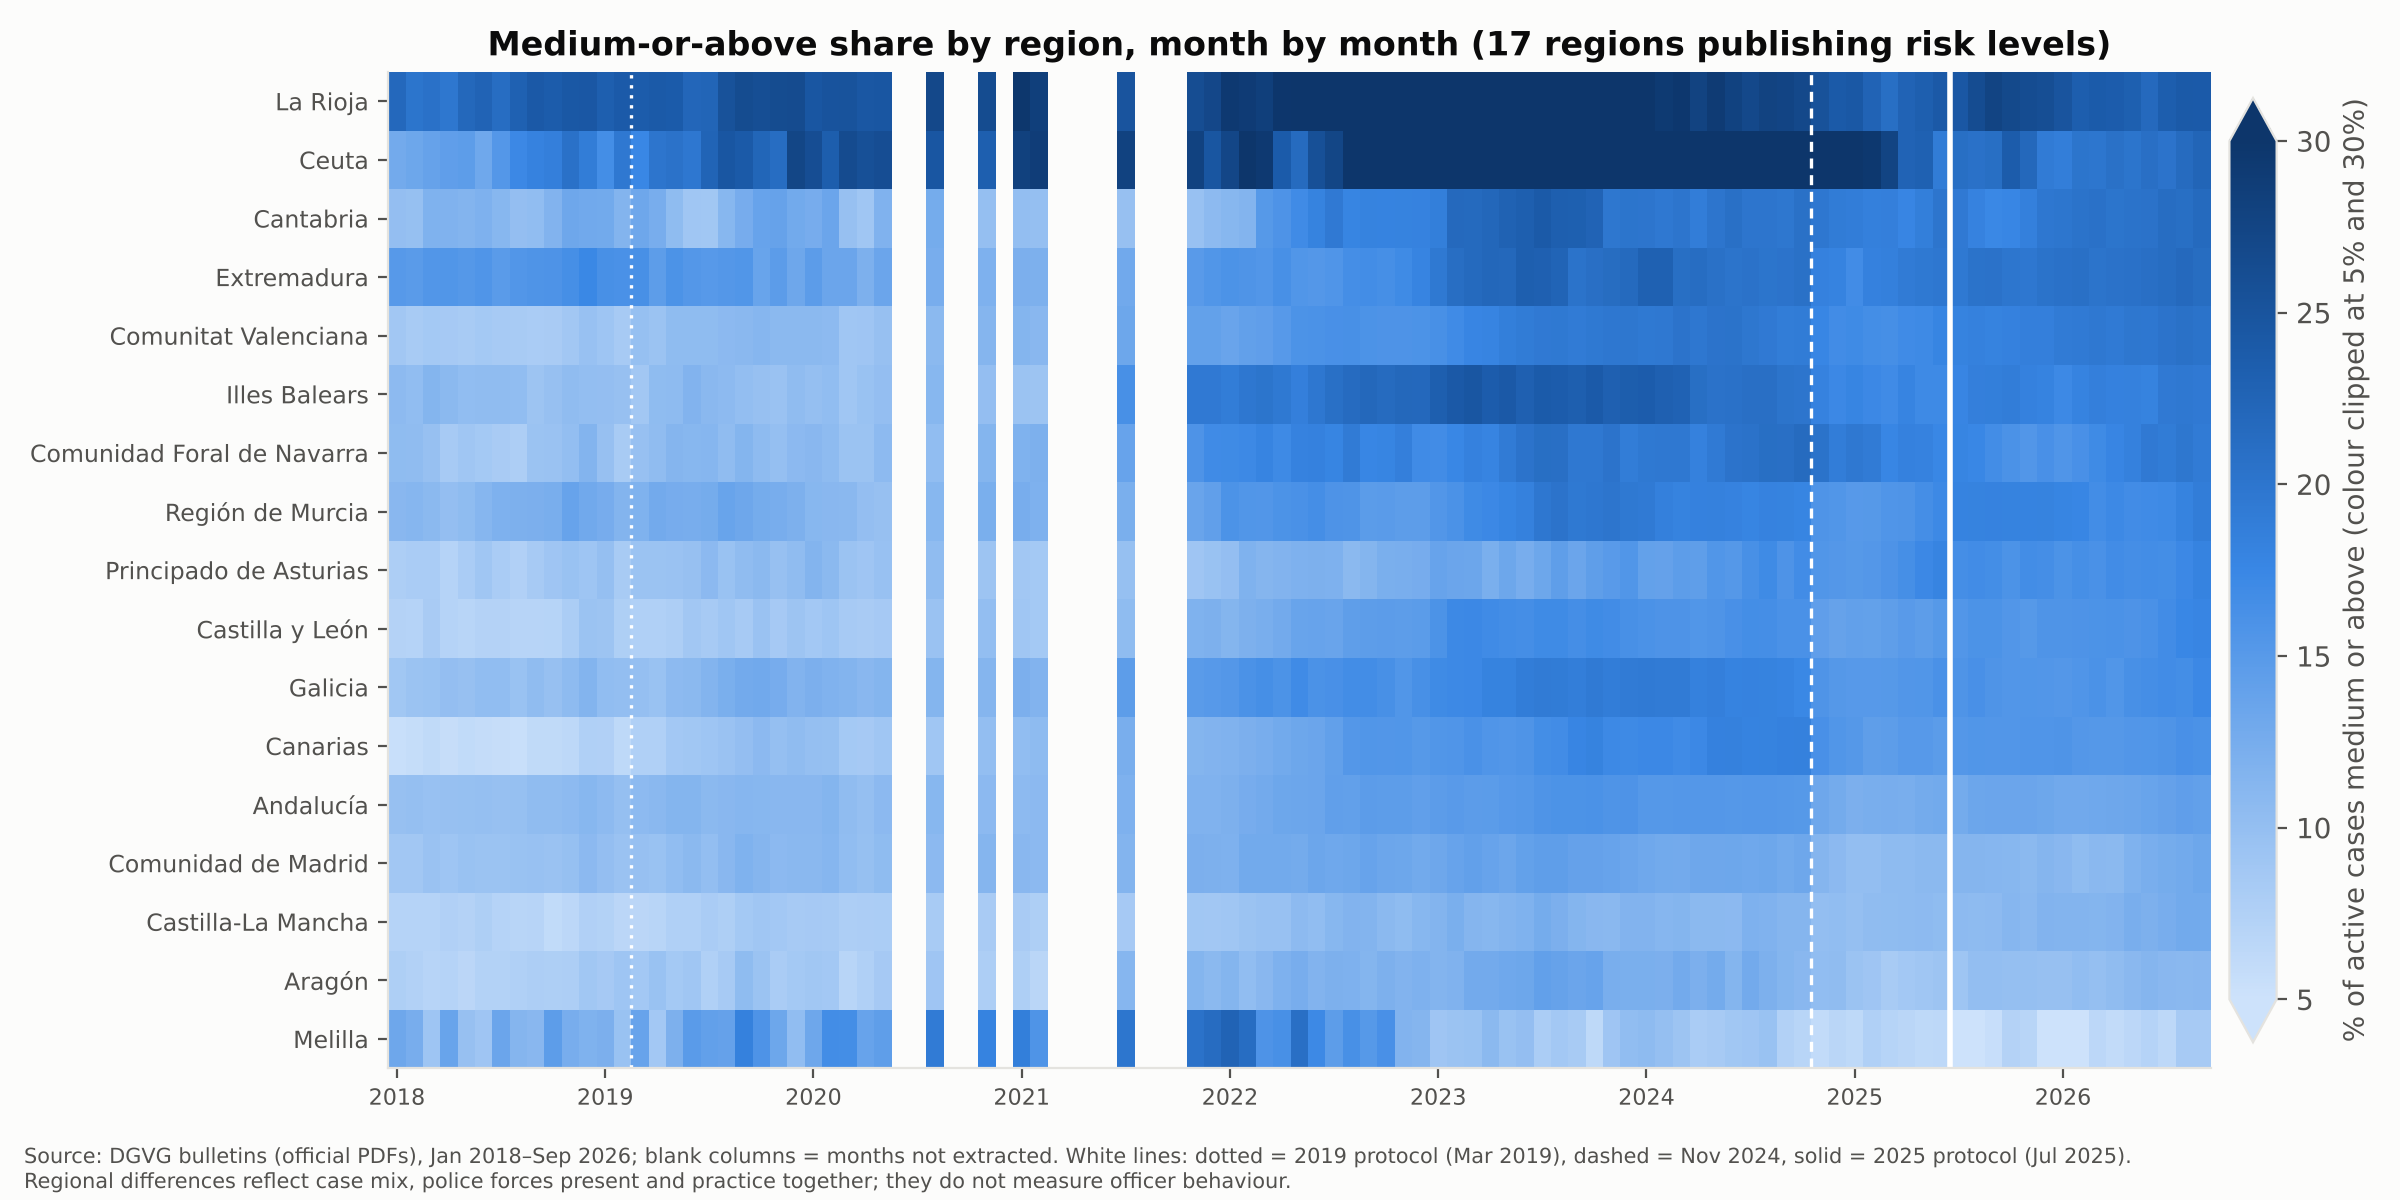

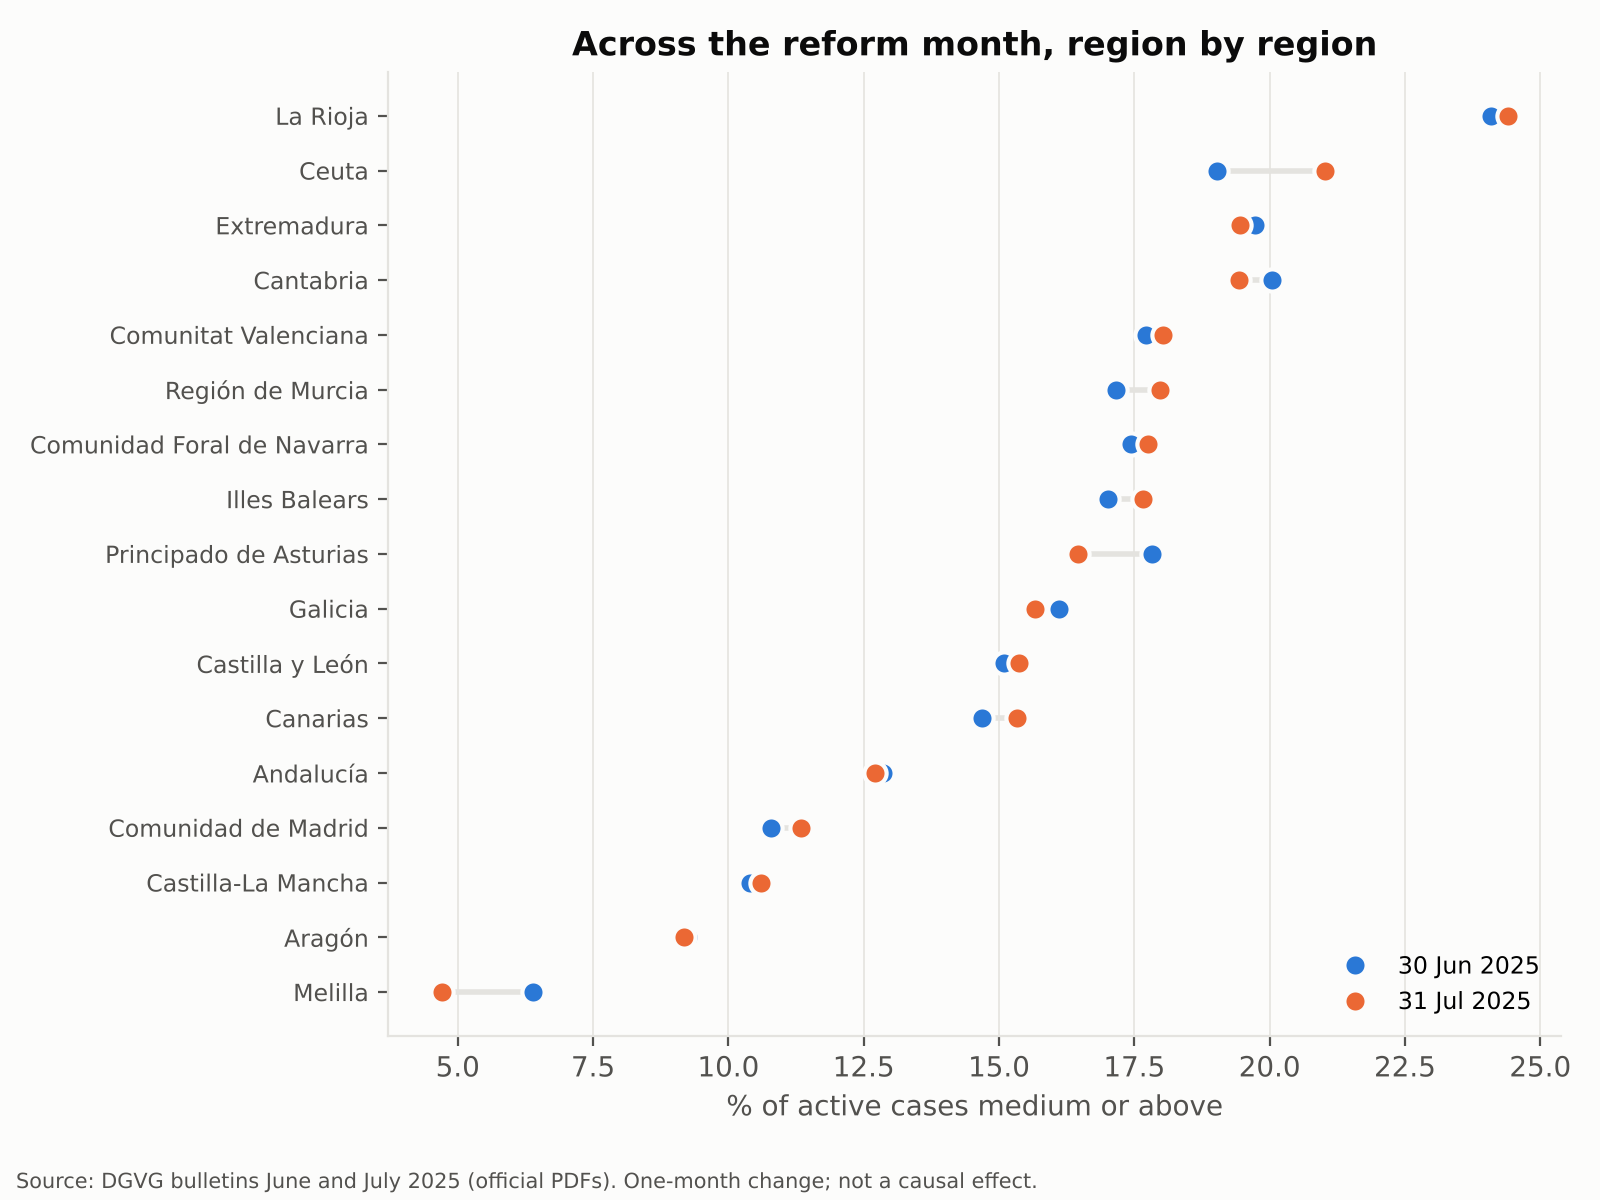

In [12]:
r = reg[reg.risk_levels_reported == True]
wide = r.pivot_table(index='unit', columns='date', values='medium_plus_pct')
snap = wide[[pd.Timestamp('2024-06-30'), pd.Timestamp('2025-06-30'), pd.Timestamp('2025-07-31'), wide.columns.max()]].round(1)
snap.columns = ['Jun 2024','Jun 2025','Jul 2025', wide.columns.max().strftime('%b %Y')]
display(snap.sort_values(snap.columns[-1], ascending=False))
spread = wide.agg(['min','median','max']).T
print('Spread of the regional medium-or-above share (percentage points), selected months:')
display((spread.loc[[pd.Timestamp('2023-01-31'), pd.Timestamp('2025-06-30'), pd.Timestamp('2025-07-31'), spread.index.max()]]).round(1))
display(Image(filename=str(figure_dir / '05_regions_medium_plus_heatmap.png')))
display(Image(filename=str(figure_dir / '07_regions_june_july_2025.png')))

group,Guardia Civil,"Local police (PL, combined)",Policía Nacional
date,,,
2020-02-29,11.77,10.11,10.52
2023-01-31,21.12,8.79,13.18
2024-06-30,23.69,8.82,13.28
2025-06-30,20.89,7.54,11.29
2025-07-31,21.32,7.38,11.28
2026-09-30,23.78,7.44,12.22


Institutions reported per month (names and numbers change; nothing is padded):


unit
23    59
25     8
24     2
36     1
21     1
Name: months, dtype: int64

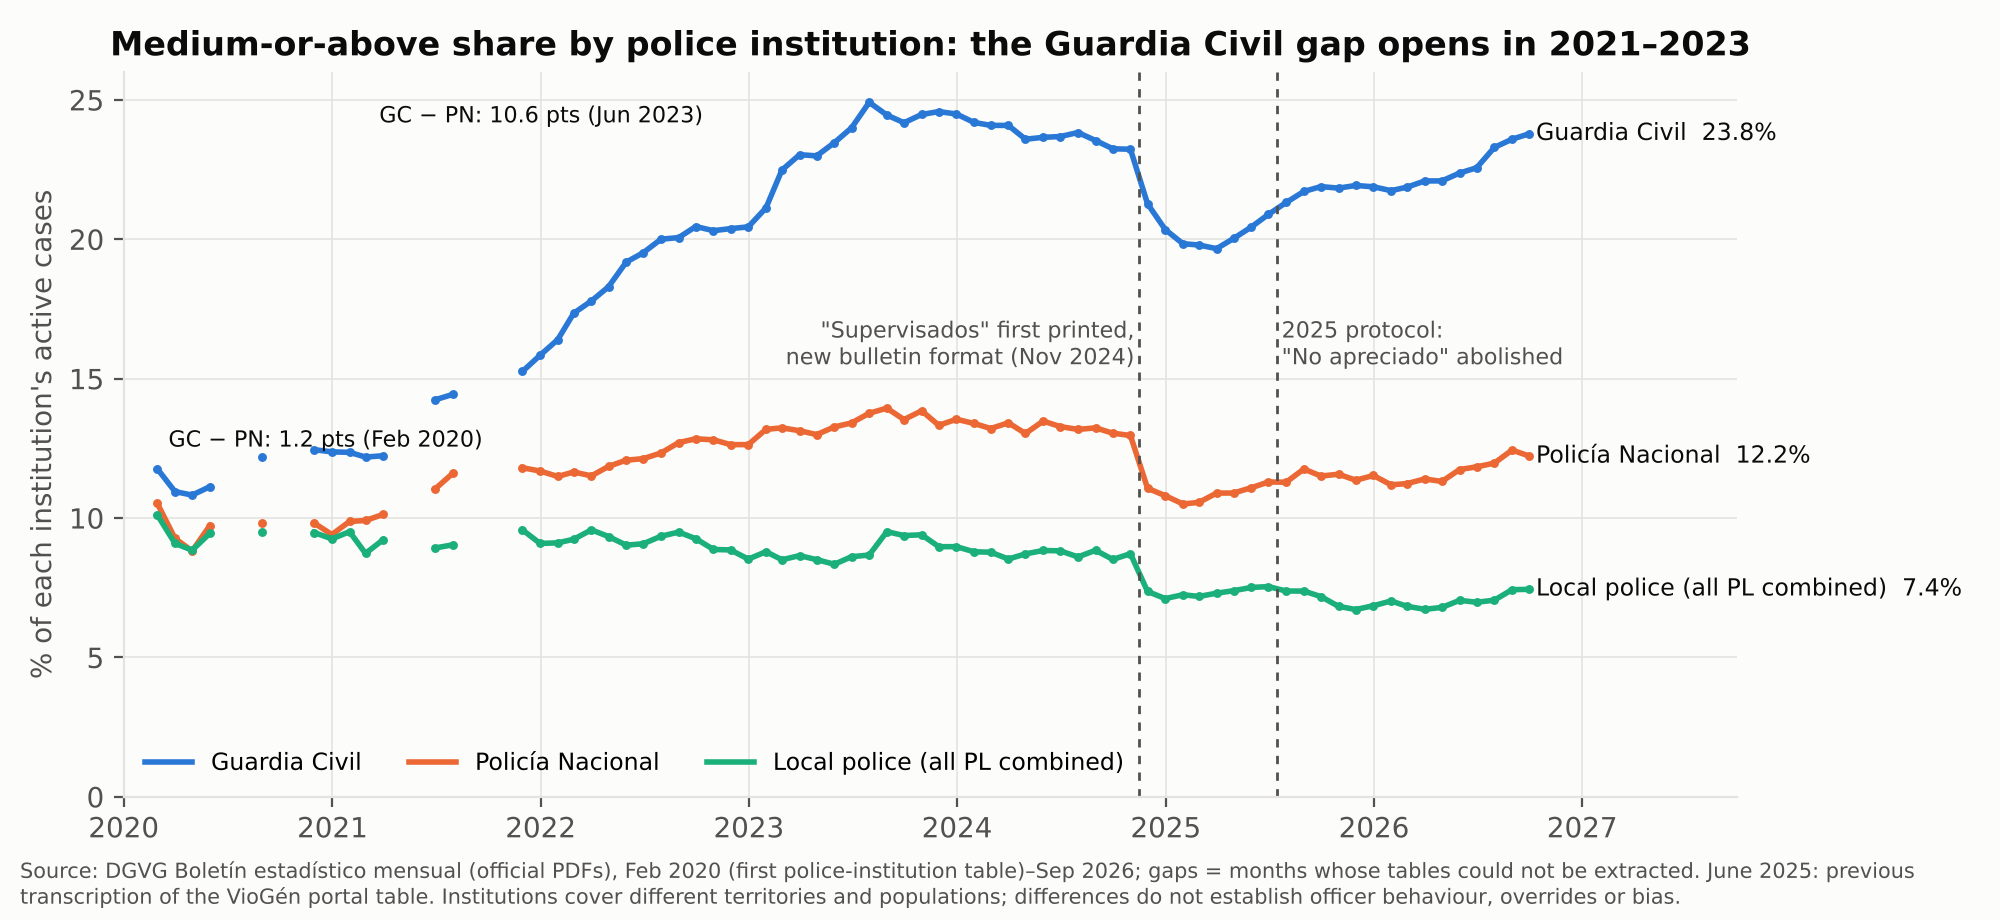

In [13]:
p = pol[pol.risk_levels_reported == True].copy()
p['group'] = np.select([p.unit.eq('Guardia Civil'), p.unit.eq('Policía Nacional'), p.unit.str.startswith('PL ')],
                       ['Guardia Civil', 'Policía Nacional', 'Local police (PL, combined)'], 'other')
g = p[p.group != 'other'].groupby(['date','group'])[['medium_plus','active']].sum()
g['medium_plus_pct'] = (100 * g.medium_plus / g.active).round(2)
gp = g.medium_plus_pct.unstack()
display(gp.loc[[d for d in pd.to_datetime(['2020-02-29','2023-01-31','2024-06-30','2025-06-30','2025-07-31']) if d in gp.index]
               + [gp.index.max()]])
print('Institutions reported per month (names and numbers change; nothing is padded):')
display(pol.groupby('date').unit.nunique().value_counts().rename('months'))
display(Image(filename=str(figure_dir / '06_police_forces_medium_plus.png')))

### The Guardia Civil gap is recent

The police-institution table starts in February 2020. The cell below follows the gap between the two state forces
and asks how much of the national rise in the medium-or-above share is a Guardia Civil phenomenon.

In [14]:
gc = p[p.unit == 'Guardia Civil'].set_index('date')[['medium_plus', 'active']]
pn = p[p.unit == 'Policía Nacional'].set_index('date')[['medium_plus', 'active']]
nn = nat.set_index('date')[['medium_plus', 'active']]
t = pd.DataFrame({'GC %': 100 * gc.medium_plus / gc.active, 'PN %': 100 * pn.medium_plus / pn.active,
                  'national %': 100 * nn.medium_plus / nn.active,
                  'national without GC %': 100 * (nn.medium_plus - gc.medium_plus) / (nn.active - gc.active),
                  'GC share of active cases %': 100 * gc.active / nn.active,
                  'GC share of medium-or-above cases %': 100 * gc.medium_plus / nn.medium_plus}).dropna()
t['GC - PN gap, pts'] = t['GC %'] - t['PN %']
sel = [d for d in pd.to_datetime(['2020-02-29','2021-03-31','2021-12-31','2022-12-31','2023-06-30','2024-10-31',
                                  '2024-11-30','2025-07-31','2026-09-30']) if d in t.index]
display(t.loc[sel].round(1))

,GC %,PN %,national %,national without GC %,GC share of active cases %,GC share of medium-or-above cases %,"GC - PN gap, pts"
date,,,,,,,
2020-02-29,11.8,10.5,10.9,10.4,39.2,42.2,1.2
2021-03-31,12.2,10.1,10.8,9.9,39.7,44.8,2.1
2021-12-31,15.8,11.7,12.9,10.9,40.4,49.7,4.2
2022-12-31,20.4,12.6,15.0,11.1,41.0,56.0,7.8
2023-06-30,24.0,13.4,16.8,11.7,41.3,59.0,10.6
2024-10-31,23.2,13.0,16.5,11.4,42.7,60.2,10.3
2024-11-30,21.3,11.1,14.7,9.8,43.1,62.2,10.2
2025-07-31,21.3,11.3,14.8,9.8,43.4,62.5,10.0
2026-09-30,23.8,12.2,16.5,10.5,45.0,64.9,11.6


**Reading.**
- **The gap opened recently.** In February 2020 the two state forces rated a similar share of their active cases
  medium or above, about a point apart. The gap opened between 2021 and mid-2023, to about 10 points, and has stayed
  there since.
- **The national rise is mostly the Guardia Civil.** From March 2021 to June 2023 the national medium-or-above share
  rose from 10.8% to 16.8%. Without the Guardia Civil it rose only from 9.9% to 11.7%. By September 2026 the Guardia
  Civil held about 45% of active cases but 65% of the medium-or-above ones.
- **The same tool and rules applied throughout.** Both forces worked under the 2019 protocol across these years.
  A divergence under one instrument is exactly where institutional discretion, training or case mix would show.
  The data cannot say which, and the Guardia Civil's caseload also grew faster.
- **The question for the interview.** What changed in the Guardia Civil's use of VioGén between 2021 and 2023?

## 6. What this means for the research question, and what it does not

* **Classification, not observed protection.** The reform's most visible effect in the published data is
  taxonomic: a category is abolished and absorbed. Whether women formerly rated "No apreciado" receive
  different protection now depends on the measures attached to "Low" in the 2025 protocol and on how they are
  applied, which these tables do not record.
* **The composition break comes before the formal reform, and it is system-wide.** The medium-or-above share
  drops most sharply in November 2024, seven months before the 2025 protocol took effect (30 June 2025).
  - *Everywhere at once.* It fell in 44 of 45 provinces, in both state police forces by the same
    amount, and in most local police forces, the same month the bulletin's format changed.
  - *Not local practice.* That pattern points to a central change, not to gradual local practice. The formal
    switch in July 2025 is almost invisible in that share.
* **Protocol changes move the categories, not the medium-or-above share.** The 2019 protocol coincided with a rise in
  "No apreciado" and a fall in "Low" in almost every province at once. The 2025 protocol folded "No apreciado" into
  "Low". Neither moved the medium-or-above share by more than about half a point in its first month.
* **Discretion moves into procedural statuses.** The *Supervisados* status, published from November 2024,
  shows follow-up being administered through rules about activation and inactivation, not only through
  risk levels (see the series in section 4).
* **Formal discretion is one-directional and unpublished.** The 2025 protocol lets the officer raise the
  automatic result, never lower it (Instrucción 1/2025, §3.8 and §6.2). The bulletins do not say how often this
  happens. This is the decisive gap between what the protocol allows and what the statistics show.
* **Institutions diverged under the same rules.** The Guardia Civil rates a larger share of its active cases
  medium or above than the Policía Nacional in every month since February 2020.
  - *Timing.* The gap was about one point in early 2020 and opened to about ten points between 2021 and mid-2023,
    under the same 2019 protocol.
  - *Weight.* Most of the national rise in those years comes from the Guardia Civil.
  - *November 2024.* The break moved both state forces by the same amount and left their gap unchanged.
  - *Limits.* The data cannot separate case mix from practice. The gap is a question for interviews, not a
    finding about officers.
* **Not observable here:** the 2025 indicators and weights, individual reclassifications, upward
  adjustments by officers, and the protection actually delivered.

## 7. Optional: reproduce one month from the official PDF

Set `RUN = True` to download one bulletin and re-extract it with the package's extractor
(`scripts/01_statistics/viogen_extract.py`). Most months use the PDF text layer. Image tables (several months in 2020–2021, and
March–September 2026) also need Tesseract (`apt-get install -y tesseract-ocr tesseract-ocr-spa`; `pip install pytesseract
opencv-python-headless`).

In [15]:
RUN = False
MONTH = '2025-07'
if RUN:
    import subprocess, sys, json
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pymupdf', 'requests'], check=True)
    sys.path.insert(0, str(scripts_dir))
    import requests, pymupdf, viogen_extract as V
    y, m = int(MONTH[:4]), int(MONTH[5:])
    url = V.BEM_URL.format(m=V.MONTHS_ES[m-1], y=y)
    pdf = Path(f'BEM_{MONTH}.pdf')
    if not pdf.exists():
        pdf.write_bytes(requests.get(url, timeout=120).content)
    doc = pymupdf.open(pdf)
    found = V.find_pages(doc, search=range(40, 90))
    prot, ddate, cols, parsed, probs = V.parse_table(found['territory'][1], 'territory')
    print(MONTH, 'protocol', prot, 'data date', ddate, '| checks failing:', V.reconcile(parsed, cols, prot, 'territory'))
    mine = {k: V.full_values(u, cols) for k, u in parsed.items()}
    panel = reg[reg.date.dt.strftime('%Y-%m') == MONTH].set_index('unit')
    same = all(mine[u]['active'] == panel.loc[u, 'active'] for u in panel.index if panel.loc[u, 'risk_levels_reported'])
    print('re-extraction matches the regional panel:', same)